In [12]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from numpy import pi

def execute_and_plot(circuit, shots):
    for index, _ in enumerate(circuit.qubits):
        circuit.measure(index, index)

    # Import the AerSimulator from Qiskit Aer for simulating quantum circuits
    backend = AerSimulator(method="statevector")  # Use the statevector method for full quantum state simulation
    # Transpile the quantum circuit to optimize it for the chosen backend
    qc_compiled = transpile(circuit, backend)

    # Run the original (not transpiled) circuit on the simulator with 32 shots (repetitions)
    job_sim = backend.run(circuits=circuit, shots=shots)

    # Retrieve the result of the simulation job
    result = job_sim.result()

    # Extract the counts (measurement outcomes and their frequencies) from the result
    counts = result.get_counts(circuit)

    # Plot a histogram of the measurement results
    return plot_histogram(counts)

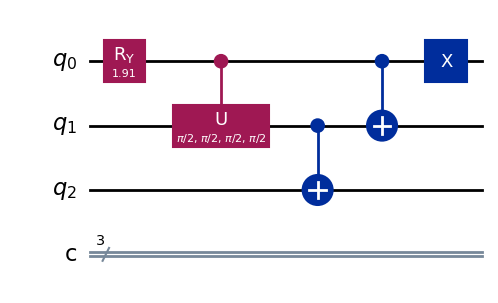

In [13]:
circuit = QuantumCircuit(3, 3)

circuit.ry(1.9106332362490184, 0)
circuit.cu(pi / 2, pi / 2, pi / 2, pi / 2, 0, 1)
circuit.cx(1, 2)
circuit.cx(0, 1)
circuit.x(0)

circuit.draw("mpl")

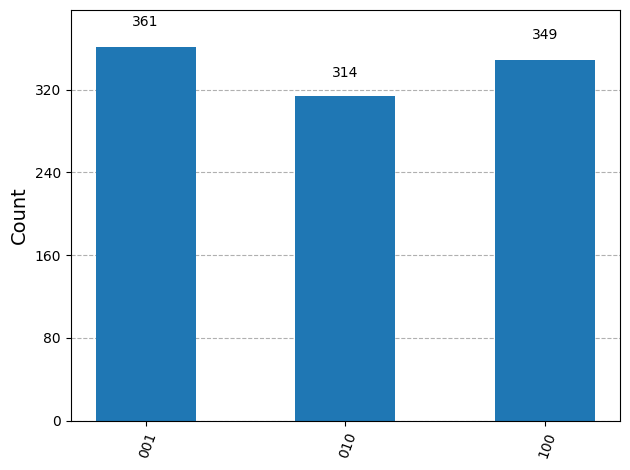

In [14]:
execute_and_plot(circuit, 1024)